In [2]:
# Score judges model's fit quality, accuracy by default
from sklearn import datasets, svm
X_digits, y_digits = datasets.load_digits(return_X_y=True)
svc = svm.SVC(C=1, kernel='linear')
svc.fit(X_digits[:-100], y_digits[:-100]).score(X_digits[-100:], y_digits[-100:])

0.98

In [3]:
# Splitting into folds, where one acts as test data and others are training
# each fold gets a chance to be the test data
# "primitive" KFold cross-validation implementation
import numpy as np
X_folds = np.array_split(X_digits, 3)
y_folds = np.array_split(y_digits, 3)
scores = list()
for k in range(3):
    # We use 'list' to copy, in order to 'pop' later on
    X_train = list(X_folds)
    X_test = X_train.pop(k)
    X_train = np.concatenate(X_train)
    y_train = list(y_folds)
    y_test = y_train.pop(k)
    y_train = np.concatenate(y_train)
    scores.append(svc.fit(X_train, y_train).score(X_test, y_test))
print(scores)

[0.9348914858096828, 0.9565943238731218, 0.9398998330550918]


In [4]:
# KFold cross-validation implementation using sklearn
from sklearn.model_selection import KFold, cross_val_score
X = ["a", "a", "a", "b", "b", "c", "c", "c", "c", "c"]
k_fold = KFold(n_splits=5)
for train_indices, test_indices in k_fold.split(X):
     print('Train: %s | test: %s' % (train_indices, test_indices))

# Performing cross-validation on splits
[svc.fit(X_digits[train], y_digits[train]).score(X_digits[test], y_digits[test])
 for train, test in k_fold.split(X_digits)]

# Score calculated using cross_val_score
print(cross_val_score(svc, X_digits, y_digits, cv=k_fold, n_jobs=-1))
# Specifying scoring criteria
print(cross_val_score(svc, X_digits, y_digits, cv=k_fold,
                scoring='precision_macro'))

Train: [2 3 4 5 6 7 8 9] | test: [0 1]
Train: [0 1 4 5 6 7 8 9] | test: [2 3]
Train: [0 1 2 3 6 7 8 9] | test: [4 5]
Train: [0 1 2 3 4 5 8 9] | test: [6 7]
Train: [0 1 2 3 4 5 6 7] | test: [8 9]
[0.96388889 0.92222222 0.9637883  0.9637883  0.93036212]
[0.96578289 0.92708922 0.96681476 0.96362897 0.93192644]


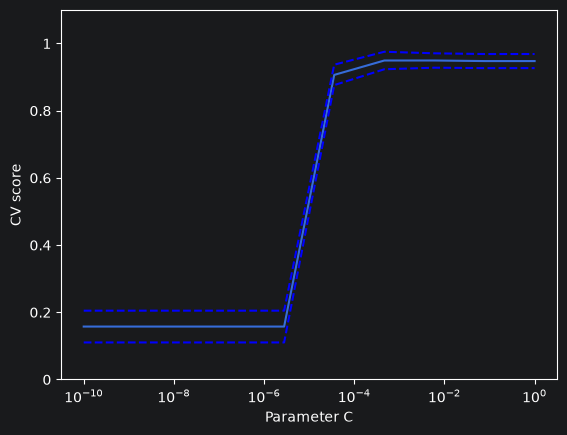

In [5]:
# On the Digits Dataset Exercise
import numpy as np
from sklearn import datasets, svm
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

X, y = datasets.load_digits(return_X_y=True)
svc = svm.SVC(kernel="linear")
C_s = np.logspace(-10, 0, 10)
scores = list()
scores_std = list()

# For each C value, train the model on the dataset and
# evaluate using cross-validation
for C in C_s:
    svc.C = C
    this_scores = cross_val_score(svc, X, y, n_jobs=1)
    scores.append(np.mean(this_scores))
    scores_std.append(np.std(this_scores))

# Plot results
plt.figure()
plt.semilogx(C_s, scores)
plt.semilogx(C_s, np.array(scores) + np.array(scores_std), "b--")
plt.semilogx(C_s, np.array(scores) - np.array(scores_std), "b--")
locs, labels = plt.yticks()
plt.yticks(locs, list(map(lambda x: "%g" % x, locs)))
plt.ylabel("CV score")
plt.xlabel("Parameter C")
plt.ylim(0, 1.1)
plt.show()

In [8]:
# Grid-search implementation using sklearn
from sklearn.model_selection import GridSearchCV, cross_val_score
Cs = np.logspace(-6, -1, 10)
clf = GridSearchCV(estimator=svc, param_grid=dict(C=Cs),
                   n_jobs=-1)
clf.fit(X_digits[:1000], y_digits[:1000])
clf.best_score_
clf.best_estimator_.C

# Prediction performance on test set is not as good as on train set
print(clf.score(X_digits[1000:], y_digits[1000:]))

# Changes from 5-fold cross-validation for regression to
# stratified 5-fold for classifiers
print(cross_val_score(clf, X_digits, y_digits) )

0.946047678795483
[0.94722222 0.91666667 0.96657382 0.97493036 0.93593315]


In [9]:
# Cross-validated estimators
from sklearn import linear_model, datasets
lasso = linear_model.LassoCV()
X_diabetes, y_diabetes = datasets.load_diabetes(return_X_y=True)
lasso.fit(X_diabetes, y_diabetes)
# The estimator chose automatically its lambda:
lasso.alpha_

np.float64(0.003753767152691846)

[0.39637586 0.3965016  0.39666738 0.39688582 0.39717347 0.39755201
 0.39804949 0.39870256 0.39955793 0.40067546 0.4021307  0.40401645
 0.40595899 0.40831035 0.41123606 0.41489643 0.41925847 0.421076
 0.42225255 0.42355228 0.4250005  0.42670509 0.42957254 0.43220384
 0.43298746 0.43133492 0.42655527 0.41765955 0.4017055  0.37593936]
[0.11863614 0.11859595 0.11854307 0.11847353 0.11838221 0.11826247
 0.11810592 0.11790171 0.11763653 0.11729368 0.11685336 0.11629296
 0.11546655 0.11437021 0.11298083 0.11129785 0.10947724 0.10803992
 0.10623187 0.10406309 0.10140152 0.09800159 0.0937298  0.08903612
 0.08378049 0.07585317 0.0669953  0.05612833 0.04655414 0.04981942]
[fold 0] alpha: 0.05968, score: 0.54209
[fold 1] alpha: 0.04520, score: 0.15521
[fold 2] alpha: 0.07880, score: 0.45192


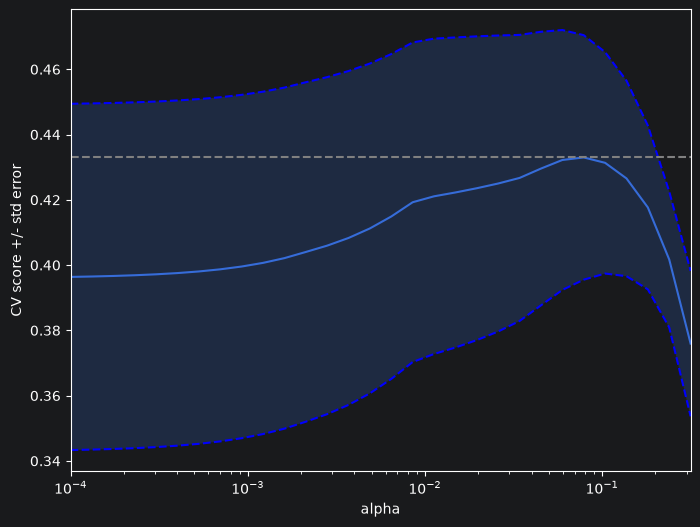

In [13]:
# On the Diabetes Dataset Example
import numpy as np

from sklearn import datasets
from sklearn.linear_model import Lasso, LassoCV
from sklearn.model_selection import GridSearchCV

# Get dataset
X, y = datasets.load_diabetes(return_X_y=True)
X = X[:150]
y = y[:150]

# Create estimator, random state set for consistency
lasso = Lasso(random_state=0, max_iter=10000)

# Define grid parameter and make it a dictionary
alphas = np.logspace(-4, -0.5, 30)
tuned_parameters = [{'alpha': alphas}]
n_folds = 5

# Cross-validator
clf = GridSearchCV(estimator=lasso, param_grid=tuned_parameters,
                   cv=n_folds, refit=False)
clf.fit(X, y)

# Get scores from cross-validator
scores = clf.cv_results_["mean_test_score"]
scores_std = clf.cv_results_["std_test_score"]


# Plotting
plt.figure().set_size_inches(8, 6)
plt.semilogx(alphas, scores)

std_error = scores_std / np.sqrt(n_folds)

plt.semilogx(alphas, scores + std_error, "b--")
plt.semilogx(alphas, scores - std_error, "b--")

# aplha=0.2 controls translucency of fill color
plt.fill_between(alphas, scores + std_error, scores - std_error, alpha=0.2)

plt.ylabel("CV score +/- std error")
plt.xlabel("alpha")
plt.axhline(np.max(scores), linestyle="--", color="0.5")
plt.xlim([alphas[0], alphas[-1]])


# How much can we trust the selected alpha?
lasso_cv = LassoCV(alphas=alphas, random_state=0, max_iter=10000)
k_fold = KFold(3)

for k, (train, test) in enumerate(k_fold.split(X, y)):
    lasso_cv.fit(X[train], y[train])
    print(
        "[fold {0}] alpha: {1:.5f}, score: {2:.5f}".format(
            k, lasso_cv.alpha_, lasso_cv.score(X[test], y[test])
        )
    )